In [409]:
import pennylane as qml
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
###
import numpy as np


# Added to silence some warnings.
jax.config.update("jax_enable_x64", True) # Enable double-precision (default is single-precision).
# jax.config.update("jax_platform_name", "cpu") # Force cpu.
# jax.config.update('jax_dynamic_shapes', True)


jax.print_environment_info()

jax:    0.4.28
jaxlib: 0.4.28
numpy:  2.3.1
python: 3.12.10 (main, May 12 2025, 15:49:11) [Clang 17.0.0 (clang-1700.0.13.3)]
jax.devices (1 total, 1 local): [CpuDevice(id=0)]
process_count: 1
platform: uname_result(system='Darwin', node='papaya.local', release='24.5.0', version='Darwin Kernel Version 24.5.0: Tue Apr 22 19:53:27 PDT 2025; root:xnu-11417.121.6~2/RELEASE_ARM64_T6041', machine='arm64')



## Configuration and Reset

In [410]:
key = jax.random.PRNGKey(42)

In [411]:
# dev = qml.device("default.qubit")
# dev = qml.device("default.qubit", shots=100) # No seed, measurement results will be the same between runs.
dev = qml.device("default.qubit", shots=100, seed=key) # No seed, measurement results will be the same between runs.

In [412]:
def is_unitary(m: jnp.ndarray):
    return jnp.allclose(jnp.eye(m.shape[0]), m * m.T.conj())

def is_hermitian(m: jnp.ndarray):
    return jnp.allclose(m, m.T.conj())

def is_sorted(x: jnp.ndarray):
    x = jnp.array(x)
    return bool(jnp.all(x[:-1] <= x[1:]))

def softmax(x: jnp.ndarray, axis=None):
    y = jnp.exp(x - jnp.max(x, axis=axis, keepdims=True)) # Stabilize to prevent overflow.
    return y / jnp.sum(y, axis=axis, keepdims=True)

In [413]:
from typing import Any, Callable

@qml.qnode(dev, interface='jax')
# @qml.qnode(dev)
# def circuit(
def dynamic_circuit(
    wires: list[int],
    funcs: list[Callable[[list[int]], None]] = [],
    func_measure: Callable[[list[int]], Any] = None,
    ):
    if not funcs:
        funcs = [lambda wires: None]
    for func in funcs:
        func(wires)
    if func_measure is not None:
        return func_measure(wires)
    else:
        return qml.state(), qml.probs(wires=wires), qml.density_matrix(wires)

In [414]:
def prepare_actions(
    wires_actions: list[int],
    action_probs_vec: jnp.ndarray, # shape (n_actions,),
    normalize: bool = False,
    ):
    # n_actions = action_probs_vec.shape[0]
    
    # d_actions = int(jnp.round(jnp.log2(n_actions)).item())
    # # print(f"{jnp.log2(n_actions)=}")
    # # print(f"{jnp.log2(n_actions).astype(jnp.int64)=}")
    # # print(f"{int(jnp.round(jnp.log2(n_actions)).item())=}")
    # # print(f"{jnp.log2(n_actions).item()=}")
    # # print(f"{d_actions=}")
    # if n_actions != 2**d_actions:
    #     raise ValueError(f"n_actions must be a power of 2, got {n_actions}.")
    
    # Create quantum state based on probability distribution for actions.
    qml.StatePrep(jnp.sqrt(action_probs_vec), wires=wires_actions, normalize=normalize) # Must normalize since inputs are probability vectors.


def prepare_returns(
    wires_actions: list[int],
    wires_returns: list[int],
    returns_probs_matrix: jnp.ndarray, # shape (n_actions, n_returns)
    normalize: bool = False,
    ):
    n_actions, n_returns = returns_probs_matrix.shape
    
    # d_returns = int(jnp.round(jnp.log2(n_returns)).item())
    # # print(f"{d_returns=}")
    # if n_returns != 2**d_returns:
    #     raise ValueError(f"n_returns must be a power of 2, got {n_returns}.")
    
    # Create operations that prepare return distributions for each action.
    # Every action index must be represented. If no returns are generated
    # for an action, then the operation should be the Identity.
    ops = [
        qml.StatePrep(jnp.sqrt(returns_probs_matrix[i]), wires=wires_returns, normalize=normalize) # Must normalize since inputs are probability vectors.
        for i in range(n_actions)
    ]
    qml.Select(ops, control=wires_actions)

In [415]:
def circuit(
    d_policies: int,
    d_actions: int,
    d_returns: int,
    action_probs_vec: jax.typing.ArrayLike,
    returns_probs_matrix: jax.typing.ArrayLike,
    U_returns_atoms: jax.typing.ArrayLike,
    n_reuploads: int,
    m_moment: int,
    ):
    """Distributional returns comparison circuit.
    Two sets of qubits: actions, and return-atoms. Kicks back expectation of return-atoms to action distribution, which in turn weights the action distribution by the relative expected return.
    """
    wires = list(range(d_policies + d_actions + d_returns))
    wires_policies = wires[:d_policies]
    wires_actions = wires[d_policies:d_policies+d_actions]
    wires_returns = wires[d_policies+d_actions:]
    
    print(f"{wires_policies=}")
    print(f"{wires_actions=}")
    print(f"{wires_returns=}")
    
    # Equal superposition of all policies.
    for w in wires_policies:
        qml.Hadamard(wires=w)
    
    prepare_actions(wires_actions=wires_actions, action_probs_vec=action_probs_vec, normalize=True)
    
    # Prepare initial action distribution, and return-atom distribution for each action.
    n_returns = int(2**d_returns)
    n_actions = int(2**d_actions)
    n_policies = int(2**d_policies)
    # for p in range(n_policies):
    #     prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix[p], normalize=True)
    ops = [
        qml.StatePrep(jnp.sqrt(returns_probs_matrix[p,a]), wires=wires_returns, normalize=True) # Must normalize since inputs are probability vectors.
        for p in range(n_policies) for a in range(n_actions)
    ]
    qml.Select(ops, control=wires_policies+wires_actions)
    
    # Apply the (non-unitary) return-atom-value operation.
    # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    for _ in range(m_moment):
        qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
    
    # Measure the return-atom qubits to collapse their state, then reset to zero.
    for w in wires_returns:
        qml.measure(wires=w, reset=True)
    
    # Re-upload initial return-atom distribution for every action, apply the return-atom-value operation, and then measure/reset to collapse the return-atom qubits.
    # n_returns = int(2**d_returns)
    # n_actions = int(2**d_actions)
    # n_reuploads = n_returns
    # n_reuploads = n_returns*2
    # n_reuploads = n_actions
    # n_reuploads = d_returns
    for k in range(n_reuploads):
        # for p in range(n_policies):
        #     prepare_returns(wires_actions=wires_actions, wires_returns=wires_returns, returns_probs_matrix=returns_probs_matrix[p], normalize=True)
        ops = [
            qml.StatePrep(jnp.sqrt(returns_probs_matrix[p,a]), wires=wires_returns, normalize=True) # Must normalize since inputs are probability vectors.
            for p in range(n_policies) for a in range(n_actions)
        ]
        qml.Select(ops, control=wires_policies+wires_actions)

        # qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
        for _ in range(m_moment):
            qml.QubitUnitary(U_returns_atoms, wires=wires_returns, unitary_check=False) # We know it's not unitary, so don't check.
        for w in wires_returns:
            qml.measure(wires=w, reset=True)
            # qml.measure(wires=w, reset=k<n_reuploads-1)
    
    return qml.probs(wires=wires_policies), qml.probs(wires=wires_actions), qml.probs(wires=wires_returns), *(qml.expval(qml.PauliZ(w)) for w in wires_actions)

In [416]:
# from functools import partial
# @partial(jax.jit, static_argnames=['d_actions', 'd_returns', 'shots'])
# def circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, shots=None):
    
#     # Device construction inside `jax.jit`.
#     dev = qml.device("default.qubit", shots=shots, seed=key)
#     qnode = qml.QNode(circuit, device=dev, interface="jax", diff_method=None)
#     return qnode(d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms)



from functools import partial
@partial(jax.jit, static_argnames=['d_policies', 'd_actions', 'd_returns', 'n_reuploads', 'm_moment', 'shots', 'name', 'diff_method'])
def circuit_jit(
    key: jax.typing.ArrayLike,
    d_policies: int,
    d_actions: int,
    d_returns: int,
    action_probs_vec: jax.typing.ArrayLike,
    returns_probs_matrix: jax.typing.ArrayLike,
    U_returns_atoms: jax.typing.ArrayLike,
    n_reuploads: int,
    m_moment: int,
    shots: int | None = None,
    name: str = "default.qubit",
    diff_method: str | None = None,
    ):
    
    # Device construction inside `jax.jit`.
    dev = qml.device(name=name, shots=shots, seed=key)
    # qnode = qml.QNode(func=circuit, device=dev, interface="jax", diff_method=diff_method)
    qnode = qml.QNode(func=circuit, device=dev, interface="jax-jit", diff_method=diff_method)
    return qnode(
        d_policies=d_policies,
        d_actions=d_actions,
        d_returns=d_returns,
        action_probs_vec=action_probs_vec,
        returns_probs_matrix=returns_probs_matrix,
        U_returns_atoms=U_returns_atoms,
        n_reuploads=n_reuploads,
        m_moment=m_moment,
        )

## Initialize Variables

In [417]:
# n_actions = 16 # 4, 8, 16, 32, 64
# n_returns = 4 # 4, 8, 16, 32, 64
# d_actions = int(jnp.round(jnp.log2(n_actions)).item())
# d_returns = int(jnp.round(jnp.log2(n_returns)).item())
d_policies = 2
d_actions = 2
d_returns = 3
n_policies = 2**d_policies
n_actions = 2**d_actions
n_returns = 2**d_returns

print(f"{n_policies=}")
print(f"{n_actions=}")
print(f"{n_returns=}")
print(f"{d_policies=}")
print(f"{d_actions=}")
print(f"{d_returns=}")

n_policies=4
n_actions=4
n_returns=8
d_policies=2
d_actions=2
d_returns=3


In [418]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([2465931498, 3679230171], dtype=uint32)


In [419]:
returns_probs_matrix = jnp.abs(jax.random.normal(key, shape=(n_policies, n_actions, n_returns)))
returns_probs_matrix = returns_probs_matrix / jnp.sum(returns_probs_matrix, axis=2, keepdims=True)  # Normalize to make it a probability vector (sums to 1).
# returns_probs_matrix = returns_probs_matrix[::-1] # Reverse.

In [420]:
returns_probs_matrix

Array([[[0.07566171, 0.01074757, 0.01200447, 0.04451968, 0.10604026,
         0.06723409, 0.5939663 , 0.08982592],
        [0.02958727, 0.19113586, 0.11855373, 0.10861413, 0.12484412,
         0.18079195, 0.14874828, 0.09772466],
        [0.00646662, 0.24955688, 0.1359338 , 0.04989532, 0.08557892,
         0.22791369, 0.17692704, 0.06772772],
        [0.22976738, 0.16795694, 0.0445901 , 0.01671909, 0.14875568,
         0.13657259, 0.15609577, 0.09954245]],

       [[0.35722572, 0.00462453, 0.00823526, 0.07135396, 0.0957181 ,
         0.1987053 , 0.04847319, 0.21566394],
        [0.18576178, 0.04227264, 0.26332945, 0.28864657, 0.02279104,
         0.03753973, 0.11503684, 0.04462195],
        [0.11954473, 0.23802165, 0.11511767, 0.05120208, 0.19682954,
         0.03836263, 0.19699999, 0.04392171],
        [0.0505421 , 0.10944979, 0.04942794, 0.19422758, 0.13362993,
         0.13008271, 0.16451155, 0.1681284 ]],

       [[0.07338413, 0.21110335, 0.0107852 , 0.16169923, 0.10257484,
       

In [421]:
returns_probs_matrix.sum(axis=2)

Array([[1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.],
       [1., 1., 1., 1.]], dtype=float64)

In [422]:
# returns_atoms_values_original = jnp.array([-1,0,1,100])
# returns_atoms_values_original = jnp.array([-10,0,1,100])
# returns_atoms_values_original = jnp.array([-100,-10,0,1])
# returns_atoms_values_original = jnp.array([-1,0,1,10])
# returns_atoms_values_original = jnp.array([-1,0,1,2])
returns_atoms_values_original = jnp.array([float(i)+1 for i in range(n_returns)])/n_returns # Shallow exponential.
# returns_atoms_values_original = jnp.array([float(i)+1 for i in range(n_returns)])/n_returns*4 # Steep exponential.
# returns_atoms_values_original = np.array([float(i)+1 for i in range(n_returns)])/n_returns*10 # Steeper exponential.
returns_atoms_values_original_normalized = softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = jax.nn.softmax(returns_atoms_values_original)
# returns_atoms_values_original_normalized = (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2) / (returns_atoms_values_original + jnp.abs(returns_atoms_values_original.min()) + 1e-2).sum() # Turn into probability distribution with some adjustment to ensure that the minimum is close to zero but not exactly zero.

# returns_atoms_values = returns_atoms_values_original_normalized.copy()
returns_atoms_values = returns_atoms_values_original_normalized.copy()
returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) # values - epsilon (epsilon is zero).
# returns_atoms_values = jnp.sqrt(returns_atoms_values * n_returns) - 3.6e-2 # values - epsilon.
returns_atoms_values = returns_atoms_values / returns_atoms_values.max() # Ensure maximum value is 1.

U_returns_atoms = jnp.diag(returns_atoms_values)

In [423]:
returns_atoms_values_original_normalized.sum()

Array(1., dtype=float64)

In [424]:
returns_atoms_values_original

Array([0.125, 0.25 , 0.375, 0.5  , 0.625, 0.75 , 0.875, 1.   ], dtype=float64)

In [425]:
returns_atoms_values

Array([0.64564853, 0.68728928, 0.73161563, 0.77880078, 0.82902912,
       0.8824969 , 0.93941306, 1.        ], dtype=float64)

In [426]:
U_returns_atoms

Array([[0.64564853, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.68728928, 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.73161563, 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.77880078, 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.82902912,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.8824969 , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.93941306, 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 1.        ]], dtype=float64)

In [427]:
# Check that `U_returns_atoms` is a contraction mapping (U.conj().T @ U <= I).
jnp.all(U_returns_atoms.conj().T @ U_returns_atoms <= np.eye(*U_returns_atoms.shape))

Array(True, dtype=bool)

In [428]:
action_probs_vec_original = [1./n_actions] * n_actions  # Uniform distribution for simplicity
action_probs_vec_original = jnp.array(action_probs_vec_original) # Convert to jax array for vectorization.
action_probs_vec = action_probs_vec_original.copy() # Preserve the original.

In [429]:
action_probs_vec

Array([0.25, 0.25, 0.25, 0.25], dtype=float64)

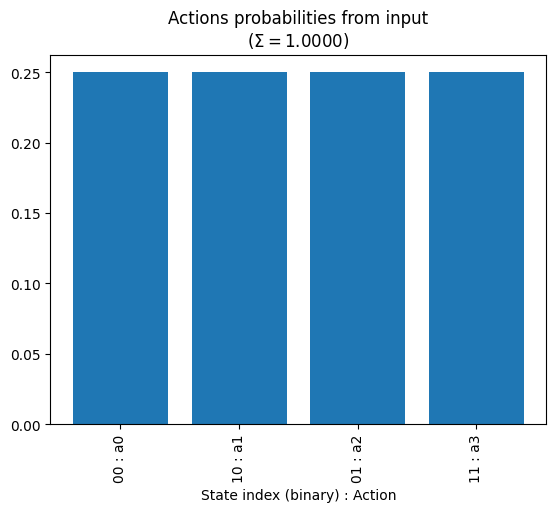

<Figure size 640x480 with 0 Axes>

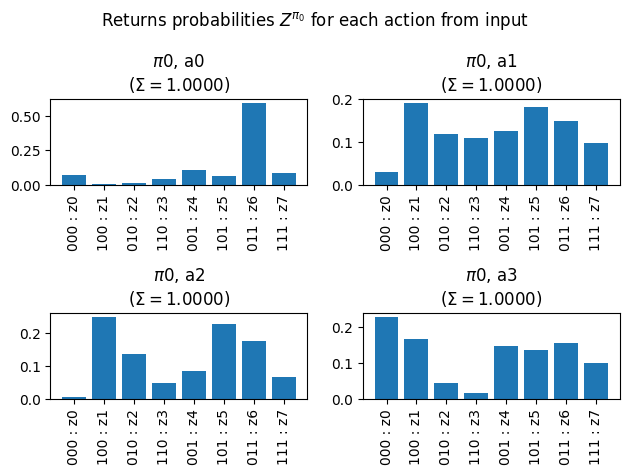

<Figure size 640x480 with 0 Axes>

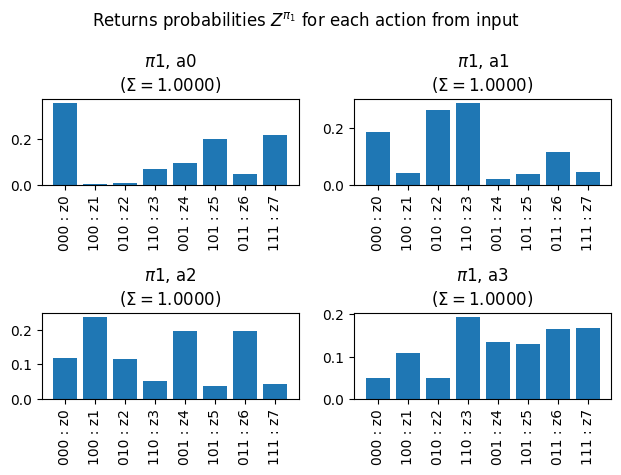

<Figure size 640x480 with 0 Axes>

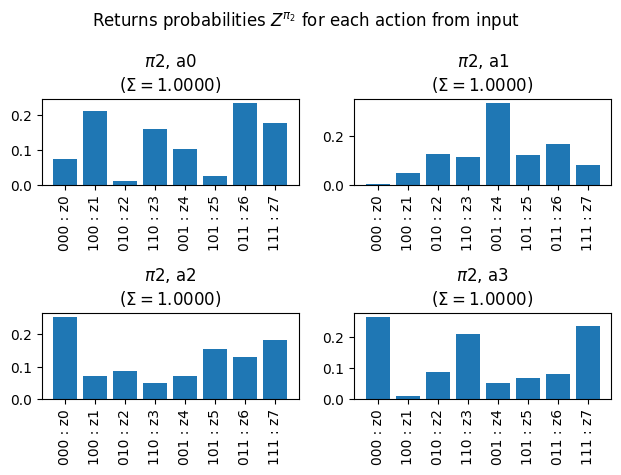

<Figure size 640x480 with 0 Axes>

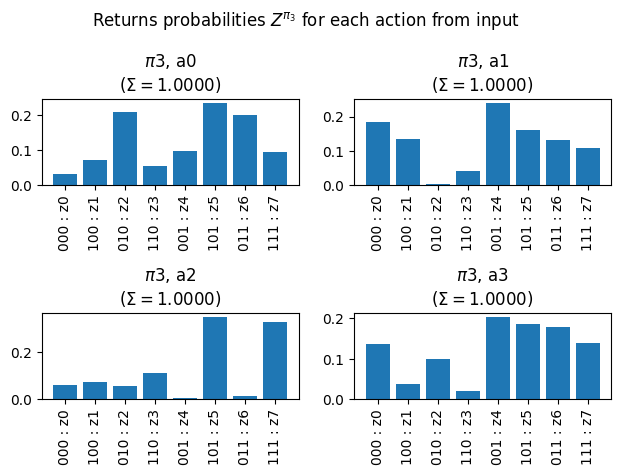

/var/folders/t7/1jlv9_sn36g96901km63r92m0000gn/T/ipykernel_64521/3529261545.py:97: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


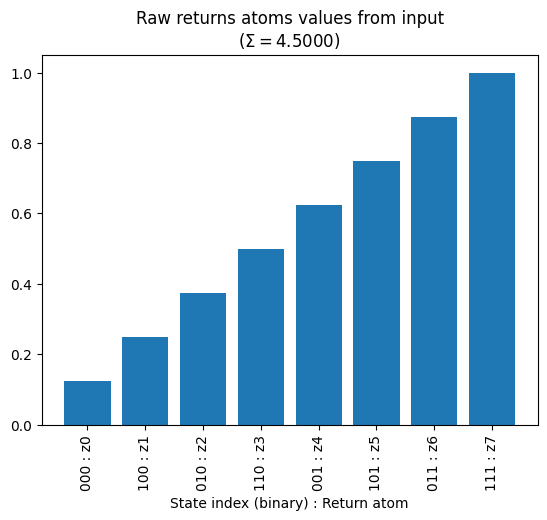

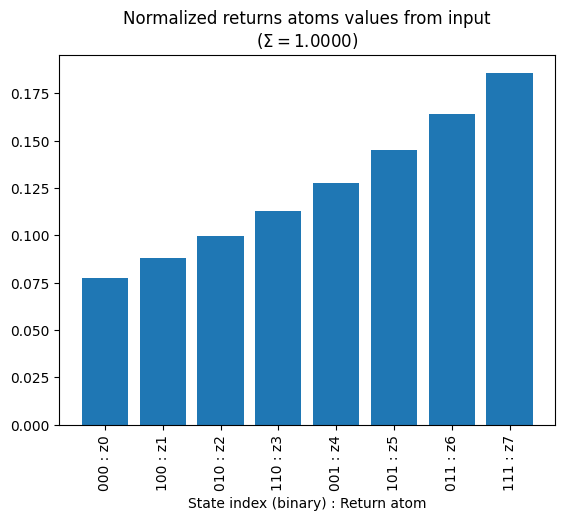

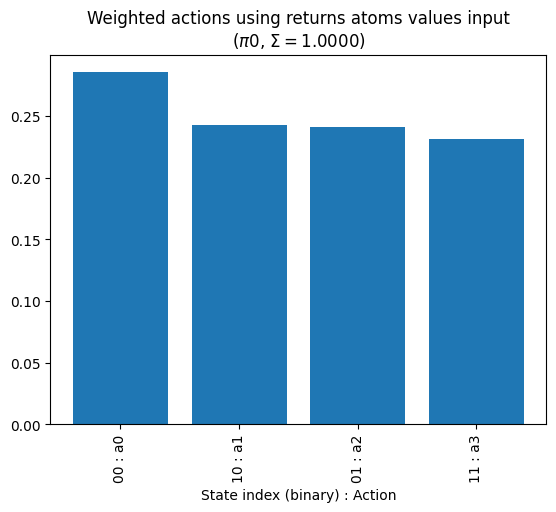

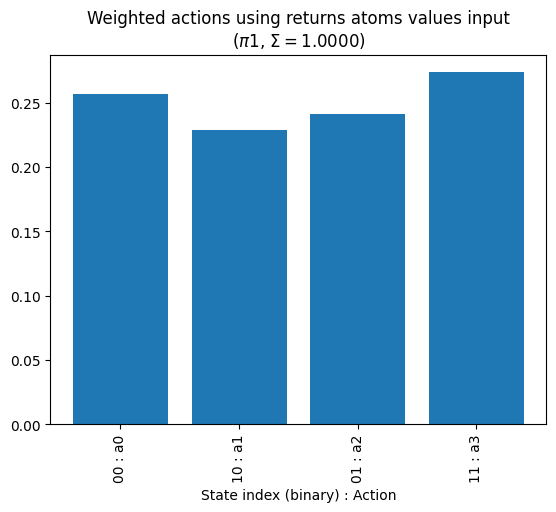

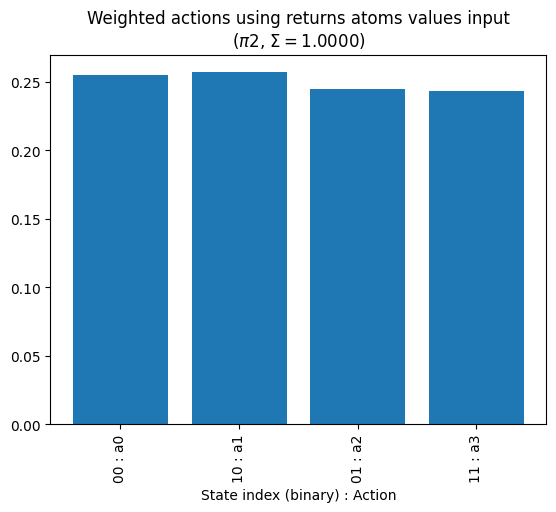

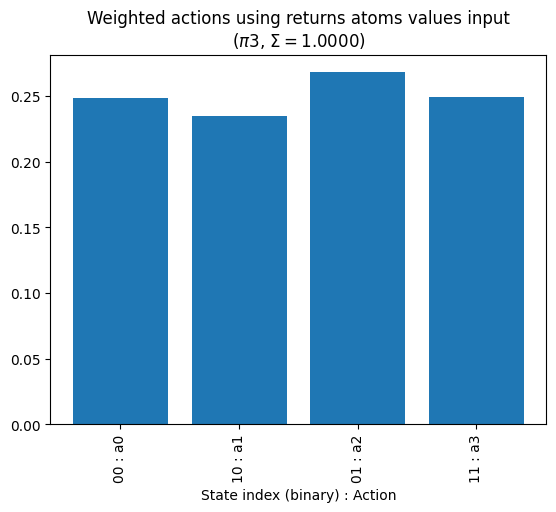

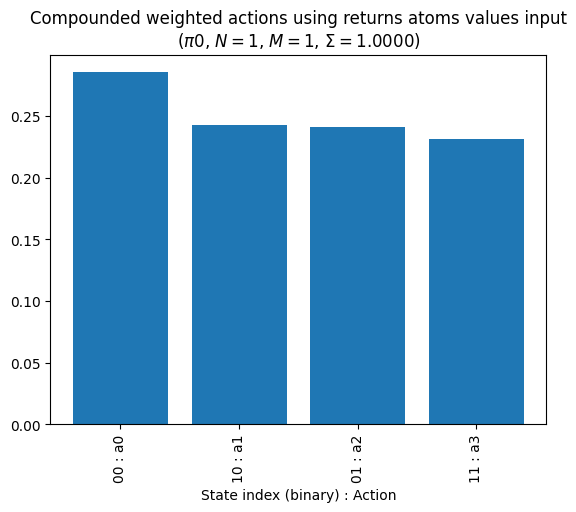

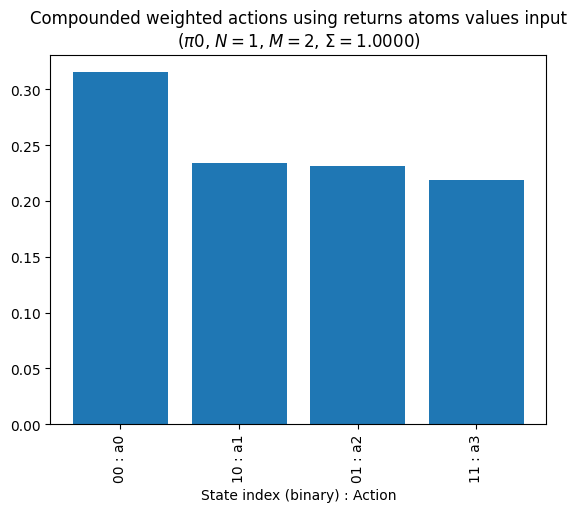

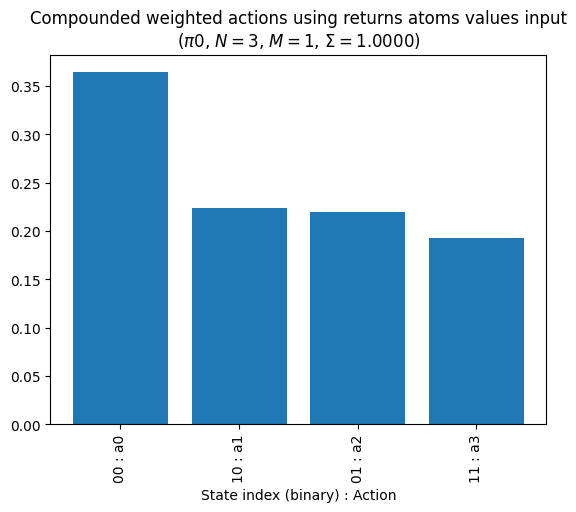

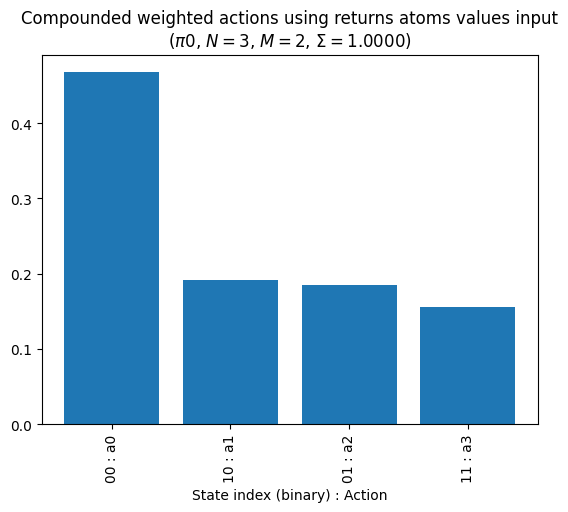

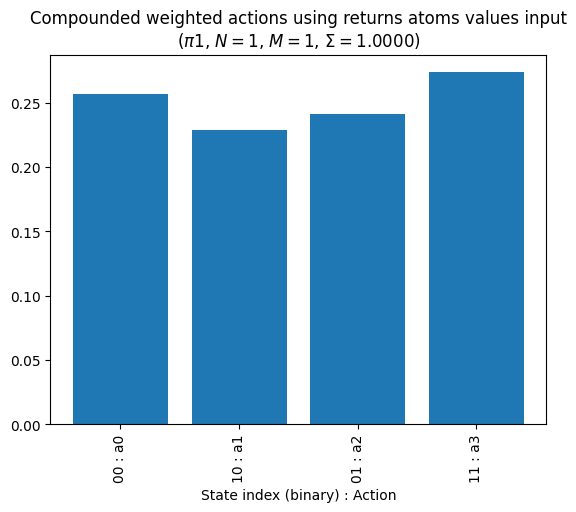

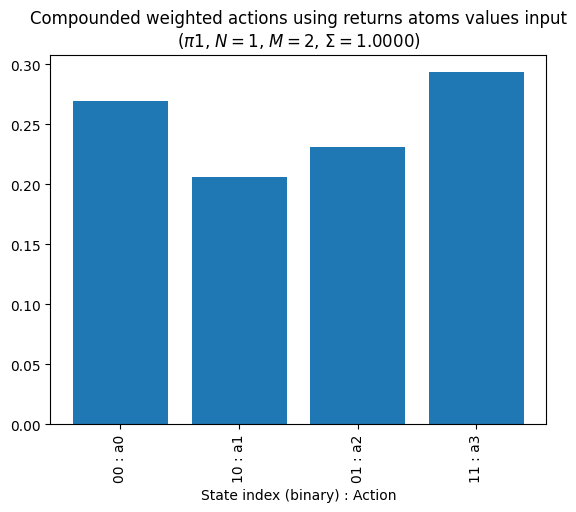

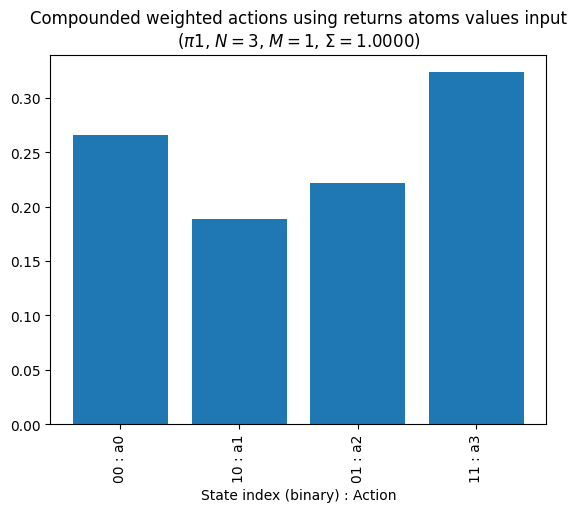

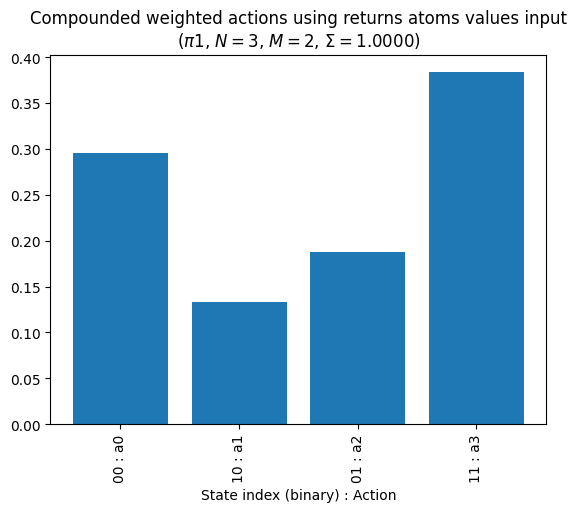

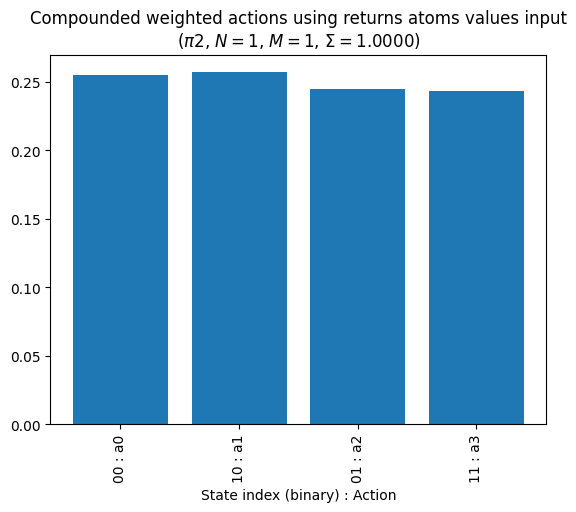

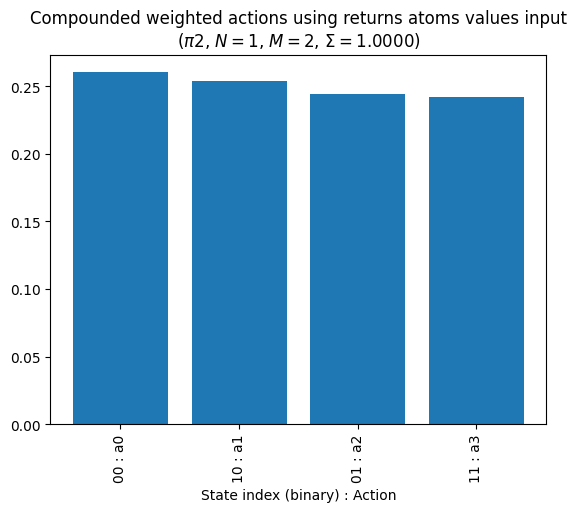

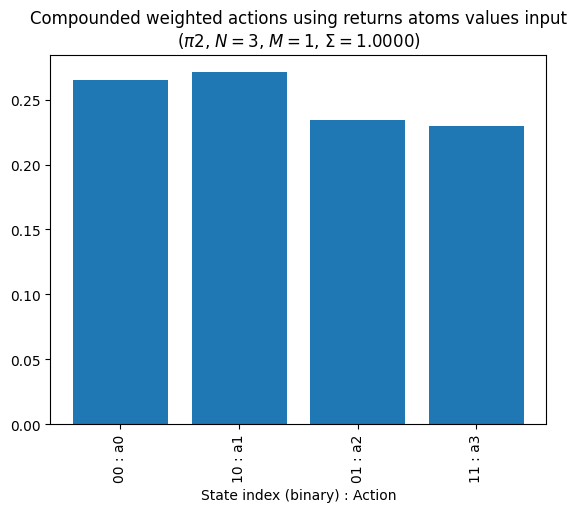

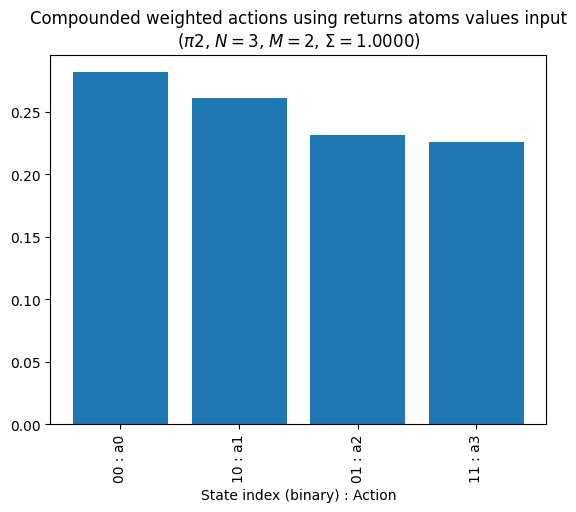

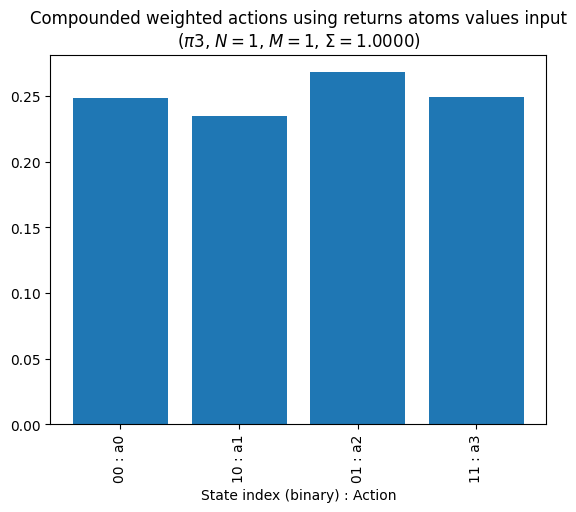

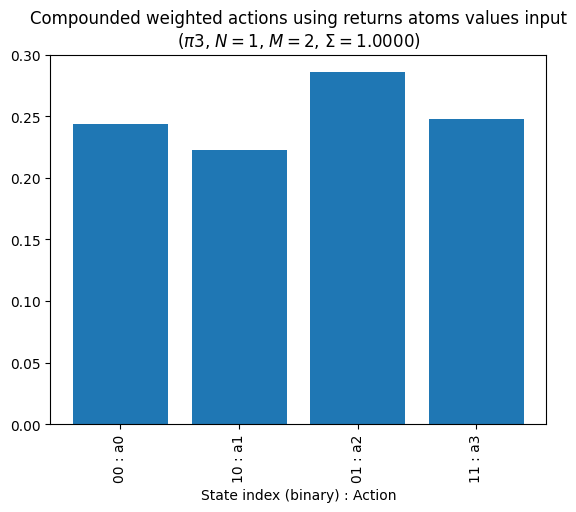

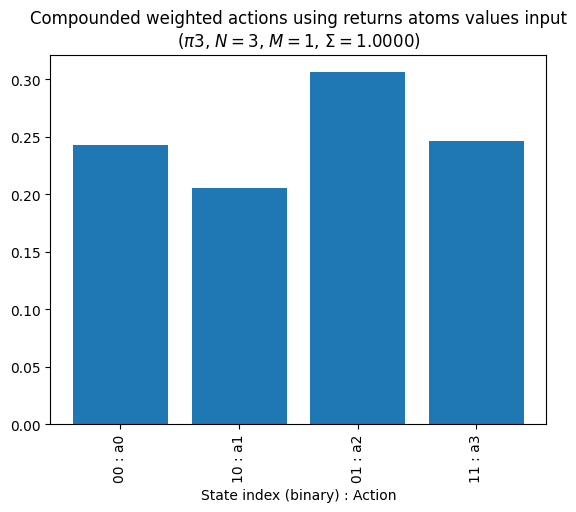

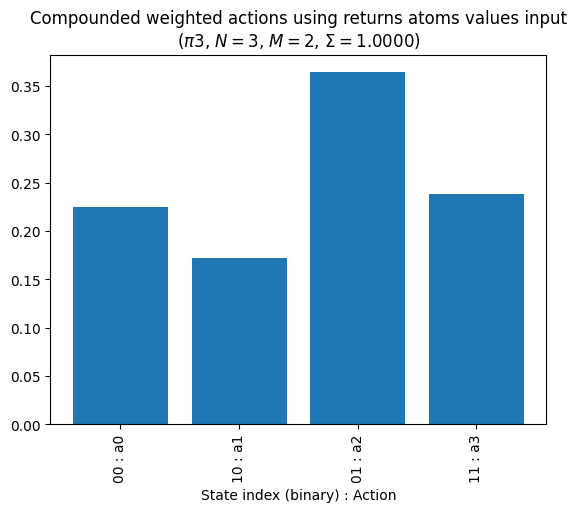

In [430]:
### Plot all inputs for visualization.

plt.figure()
plt.bar(jnp.arange(n_actions), action_probs_vec)
plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from input\n($\\Sigma = {action_probs_vec.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")


for p in range(n_policies):
    plt.figure()
    d = int(jnp.ceil(jnp.sqrt(n_actions)))
    fig, axs = plt.subplots(d, d)
    axs = axs.flatten()
    for a in range(n_actions):
        y = returns_probs_matrix[p,a]
        axs[a].bar(jnp.arange(n_returns), y)
        axs[a].set_xticks(jnp.arange(n_returns))
        axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
        axs[a].set_title(f"$\\pi${p}, a{a}\n($\\Sigma = {y.sum():.4f}$)")
    plt.suptitle(f"Returns probabilities $Z^{{\\pi_{p}}}$ for each action from input")
    plt.tight_layout()
    plt.show()


plt.figure()
plt.bar(jnp.arange(n_returns), returns_atoms_values_original)
plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Raw returns atoms values from input\n($\\Sigma = {returns_atoms_values_original.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

plt.figure()
plt.bar(jnp.arange(n_returns), returns_atoms_values_original_normalized)
plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
plt.title(f"Normalized returns atoms values from input\n($\\Sigma = {returns_atoms_values_original_normalized.sum():.4f}$)")
plt.xlabel("State index (binary) : Return atom")

# #########

# plt.figure()
# df = pd.DataFrame(returns_probs_matrix, columns=[f"z{i}" for i in range(n_returns)], index=[f"a{i}" for i in range(n_actions)])
# weights = pd.Series(action_probs_vec, index=[f"a{i}" for i in range(n_actions)])
# y = (df.T * weights).sum(axis=1).to_numpy()
# plt.bar(jnp.arange(n_returns), y)
# plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
# plt.title(f"Sum of weighted returns using action distribution from input\n($\\Sigma = {y.sum():.4f}$)")
# plt.xlabel("State index (binary) : Return atom")


# plt.figure()
# M = jnp.einsum('jj,ij->j', U_returns_atoms, returns_probs_matrix)
# y = jnp.abs(M)
# plt.bar(jnp.arange(n_returns), y)
# plt.xticks(jnp.arange(n_returns), [f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
# plt.title(f"Sum of weighted returns using returns atoms values from input\n($\\Sigma = {y.sum():.4f}$)")
# plt.xlabel("State index (binary) : Return atom")

# plt.figure()
# d = int(jnp.ceil(jnp.sqrt(n_actions)))
# fig, axs = plt.subplots(d, d)
# axs = axs.flatten()
# for a in range(n_actions):
#     y = returns_probs_matrix[a] * returns_atoms_values_original_normalized
#     axs[a].bar(jnp.arange(n_returns), y)
#     axs[a].set_xticks(jnp.arange(n_returns))
#     axs[a].set_xticklabels([f"{i:0{d_returns}b}"[::-1] + f" : z{i}" for i in range(n_returns)], rotation=90)
#     axs[a].set_title(f"a{a}\n($\\Sigma = {y.sum():.4f}$)")
# plt.suptitle("Weighted returns using atom values from input")
# plt.tight_layout()
# plt.show()

# #########

for p in range(n_policies):
    plt.figure()
    y = (returns_probs_matrix[p] @ returns_atoms_values_original_normalized) # Perform expected value once.
    y /= y.sum() # Normalize.
    plt.bar(jnp.arange(n_actions), y)
    plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
    plt.title(f"Weighted actions using returns atoms values input\n($\\pi${p}, $\\Sigma = {y.sum():.4f}$)")
    plt.xlabel("State index (binary) : Action")

# plt.figure()
# # N = n_returns
# # N = d_returns
# N = 1
# y = (returns_probs_matrix @ returns_atoms_values_original_normalized)**N # Perform expected value, then compound result multiple times
# y /= y.sum() # Normalize.
# plt.bar(jnp.arange(n_actions), y)
# plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
# plt.title(f"Compounded weighted actions using returns atoms values input\n($N={N}$, $\\Sigma = {y.sum():.4f}$)")
# plt.xlabel("State index (binary) : Action")
# print(f"Compounded: {y}")

for p in range(n_policies):
    for N, M in [(1,1), (1,2), (d_returns,1), (d_returns,2)]: # (N,M)
        plt.figure()
        # N = n_returns
        # N = d_returns
        # N = 1
        # M = 1
        y = (returns_probs_matrix[p] @ (returns_atoms_values_original_normalized ** M))**N # Perform expected value, then compound result multiple times
        y /= y.sum() # Normalize.
        plt.bar(jnp.arange(n_actions), y)
        plt.xticks(jnp.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
        plt.title(f"Compounded weighted actions using returns atoms values input\n($\\pi${p}, $N={N}$, $M={M}$, $\\Sigma = {y.sum():.4f}$)")
        plt.xlabel("State index (binary) : Action")
        # print(f"Compounded: {y}")

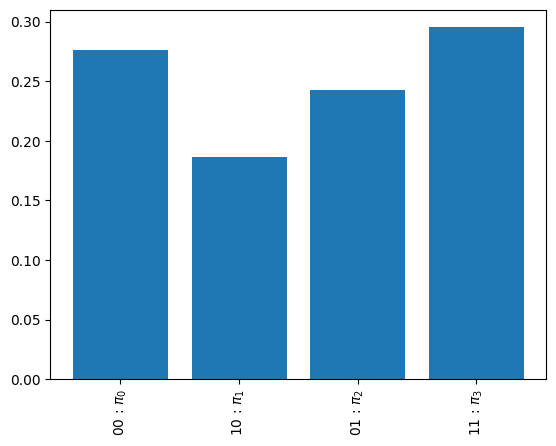

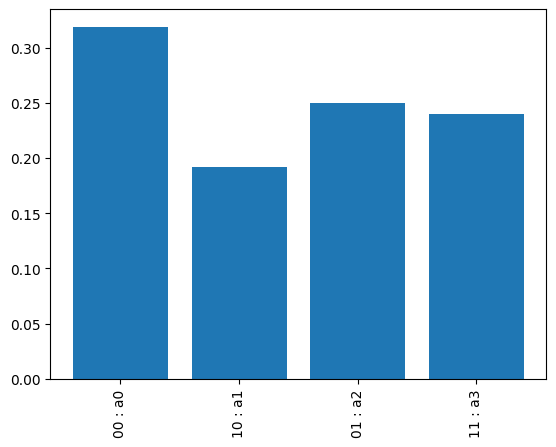

In [573]:
# y = (returns_probs_matrix @ returns_atoms_values_original_normalized) # Perform expected value once.
y = (returns_probs_matrix @ (returns_atoms_values_original_normalized ** M))**N
y /= y.sum() # Normalize.
y, y.sum(axis=1)

plt.figure()
plt.bar(np.arange(n_policies), y.sum(axis=1))
plt.xticks(np.arange(n_policies), [f"{i:0{d_policies}b}"[::-1] + f" : $\\pi_{{{i}}}$" for i in range(n_policies)], rotation=90);
plt.show();

plt.figure()
plt.bar(np.arange(n_actions), y.sum(axis=0))
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90);
plt.show();

## Build and Run Circuit

In [566]:
# Number of times to re-upload return-atoms.
# n_reuploads = d_returns
# n_reuploads = d_returns + int(d_returns/2)
# n_reuploads = d_returns*2
n_reuploads = 3
m_moment = 1
print(f"{n_reuploads=}")

n_reuploads=3


In [567]:
# Print the circuit to ensure it is what we expect.
print(qml.draw(circuit)(d_policies, d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, n_reuploads, m_moment))

wires_policies=[0, 1]
wires_actions=[2, 3]
wires_returns=[4, 5, 6]
0: ──H───╭Select──────────────────╭Select──────────────────╭Select──────────────────╭Select ···
1: ──H───├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
2: ─╭|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
3: ─╰|Ψ⟩─├Select──────────────────├Select──────────────────├Select──────────────────├Select ···
4: ──────├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select─╭U(M0)──┤↗│  │0⟩─├Select ···
5: ──────├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select─├U(M0)──┤↗│  │0⟩─├Select ···
6: ──────╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select─╰U(M0)──┤↗│  │0⟩─╰Select ···

0: ··· ──────────────────┤ ╭Probs     
1: ··· ──────────────────┤ ╰Probs     
2: ··· ──────────────────┤ ╭Probs  <Z>
3: ··· ──────────────────┤ ╰Probs  <Z>
4: ··· ─╭U(M0)──┤↗│  │0⟩─┤ ╭Probs     
5: ··· ─├U(M0)──┤↗│  │0⟩─┤ ├Probs     
6: ··· ─╰U(M0)──┤↗│  │0⟩─┤

In [568]:
key, _ = jax.random.split(key)
print(f"{key=}")

key=Array([2799086204, 3111214095], dtype=uint32)


In [569]:
name = "default.qubit"
# shots = None # Exact numerical simulation.
# shots = 100
shots = 1_000
# shots = 10_000
diff_method = None
# diff_method = "backprop"
# diff_method = "parameter-shift"

# (probs_actions, probs_returns) = circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix, U_returns_atoms, shots=shots)
# (probs_actions, probs_returns) = circuit_jit(key, d_actions, d_returns, action_probs_vec, returns_probs_matrix)

(probs_policies, probs_actions, probs_returns, *expval_actions) = circuit_jit(
    key=key,
    d_policies=d_policies,
    d_actions=d_actions,
    d_returns=d_returns,
    action_probs_vec=action_probs_vec,
    returns_probs_matrix=returns_probs_matrix,
    U_returns_atoms=U_returns_atoms,
    n_reuploads=n_reuploads,
    m_moment=m_moment,
    name=name,
    shots=shots,
    diff_method=diff_method,
    )

print(f"{probs_policies=}")
print(f"{probs_actions=}")
print(f"{probs_returns=}")
print(f"{expval_actions[::-1]=} --> converts to {((jnp.array(expval_actions) < 0).astype(int))[::-1]}") # Reverse the actions expectations for left-to-right bit-accurate readout.

probs_policies=Array([0.28 , 0.177, 0.223, 0.32 ], dtype=float64)
probs_actions=Array([0.315, 0.201, 0.223, 0.261], dtype=float64)
probs_returns=Array([1., 0., 0., 0., 0., 0., 0., 0.], dtype=float64)
expval_actions[::-1]=[Array(0.158, dtype=float64), Array(0.046, dtype=float64)] --> converts to [0 0]


Text(0.5, 0, 'State index (binary) : Action')

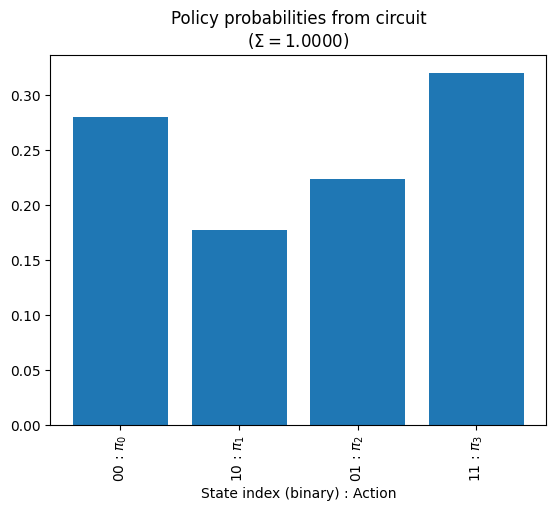

In [570]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_policies), probs_policies)
plt.xticks(np.arange(n_policies), [f"{i:0{d_policies}b}"[::-1] + f" : $\\pi_{{{i}}}$" for i in range(n_policies)], rotation=90)
plt.title(f"Policy probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

Text(0.5, 0, 'State index (binary) : Action')

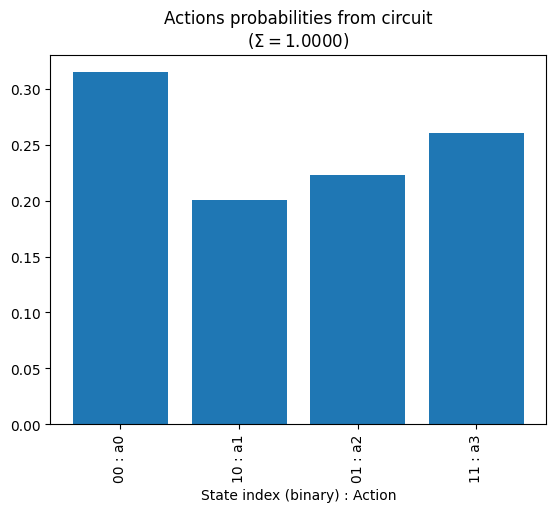

In [571]:
### Probabilities derived from measuring the returns qubits in the circuit.
### NOTE - I've found that the result plotted below will be scaled by a factor of 1/n_actions.

plt.bar(np.arange(n_actions), probs_actions)
plt.xticks(np.arange(n_actions), [f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
plt.title(f"Actions probabilities from circuit\n($\\Sigma = {probs_actions.sum():.4f}$)")
plt.xlabel("State index (binary) : Action")

In [572]:
from collections import namedtuple
ActionRank = namedtuple("ActionRank", ["action", "rank"])

### Rank actions from high-to-low based on their weighted expected return.

action_rank_manual_compute, _ = zip(*sorted(list(enumerate(returns_probs_matrix @ returns_atoms_values_original)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_manual_compute = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_manual_compute)) # [(action_index, rank), ...]
print(f"action_rank_manual_compute={[a for a,r in action_rank_manual_compute]}")

### Rank actions from high-to-low based on their circuit probability.

action_rank_circuit_probs, _ = zip(*sorted(list(enumerate(probs_actions)), key=lambda tup: tup[1])[::-1]) # List of action indices where location in list indicates action rank in descending order (high -> low).
action_rank_circuit_probs = list(ActionRank(action, rank) for rank,action in enumerate(action_rank_circuit_probs)) # [(action_index, rank), ...]
print(f"action_rank_circuit_probs={[a for a,r in action_rank_circuit_probs]}")

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

In [ ]:
### Verify manually computed action rank is the same as the rank estimated by the circuit.

action_rank_manual_compute == action_rank_circuit_probs

True

In [ ]:
# Check if the top 3 actions are identical.
action_rank_manual_compute[:3] == action_rank_circuit_probs[:3]

True

In [ ]:
# Check if the top 3 ranks consist of the same action pool (not necessarily the same positions).
set(a for a, r in action_rank_manual_compute[:3]) == set(a for a, r in action_rank_circuit_probs[:3])

True

Text(0.5, 1.0, 'Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = True\nTop 3 rank match = True (jumbled match? True)\nTop 1 rank match = True')

<Figure size 640x480 with 0 Axes>

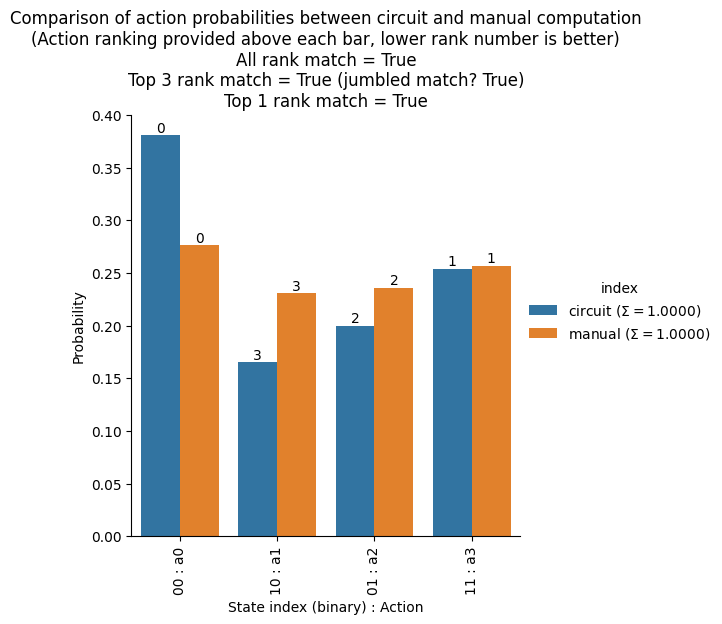

In [ ]:
### To make visual comparison easier, plot action probabilities from quantum circuit and manual computation together on same chart.

# Compute manual returns probabilities.
# y = returns_probs_matrix @ returns_atoms_values_original
y = returns_probs_matrix @ returns_atoms_values_original_normalized
y /= y.sum()

# Plot circuit action probabilities and manual computation action probabilities together.
df = pd.DataFrame(np.array([probs_actions, y]), columns=[f"a{i}" for i in range(n_actions)], index=[f"circuit ($\\Sigma = {probs_actions.sum():.4f}$)", f"manual ($\\Sigma = {y.sum():.4f}$)"])
df = df.reset_index()
df = df.melt(id_vars='index')

plt.figure()
g = sns.catplot(data=df, x='variable', y='value', hue='index', kind="bar", legend=True)
ax = g.facet_axis(0, 0)
for idx, (container, actionrank) in enumerate(zip(ax.containers, [action_rank_circuit_probs, action_rank_manual_compute])):
    # labels = [f"{v.get_height():.4f}" for v in container]
    actionrank = sorted(actionrank, key=lambda ar: ar.action)
    labels = [f"{actionrank[j].rank}" for j, v in enumerate(container)]
    ax.bar_label(container, labels=labels, label_type='edge')
g.set_xticklabels([f"{i:0{d_actions}b}"[::-1] + f" : a{i}" for i in range(n_actions)], rotation=90)
g.set_xlabels("State index (binary) : Action")
g.set_ylabels("Probability")
plt.title(f"Comparison of action probabilities between circuit and manual computation\n(Action ranking provided above each bar, lower rank number is better)\nAll rank match = {action_rank_manual_compute == action_rank_circuit_probs}\nTop 3 rank match = {action_rank_manual_compute[:3] == action_rank_circuit_probs[:3]} (jumbled match? {set(a for a, r in action_rank_manual_compute[:3]) == set(a for a, r in action_rank_circuit_probs[:3])})\nTop 1 rank match = {action_rank_manual_compute[0] == action_rank_circuit_probs[0]}")